
### 1. Librairy import


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.plotting.backend = "plotly"

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.neighbors import KNeighborsClassifier

### 2. Data import

In [2]:
df=pd.read_csv("dataset.csv")
df.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,True
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,True
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,True
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,True
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,True


### 3. Data Description.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   radius_mean              569 non-null    float64
 1   texture_mean             569 non-null    float64
 2   perimeter_mean           569 non-null    float64
 3   area_mean                569 non-null    float64
 4   smoothness_mean          569 non-null    float64
 5   compactness_mean         569 non-null    float64
 6   concavity_mean           569 non-null    float64
 7   concave points_mean      569 non-null    float64
 8   symmetry_mean            569 non-null    float64
 9   fractal_dimension_mean   569 non-null    float64
 10  radius_se                569 non-null    float64
 11  texture_se               569 non-null    float64
 12  perimeter_se             569 non-null    float64
 13  area_se                  569 non-null    float64
 14  smoothness_se            569 non-null

In [4]:
df.describe(include='all')

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,malignant
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,357
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN


In [5]:
df.columns

Index(['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'malignant'],
      dtype='str')

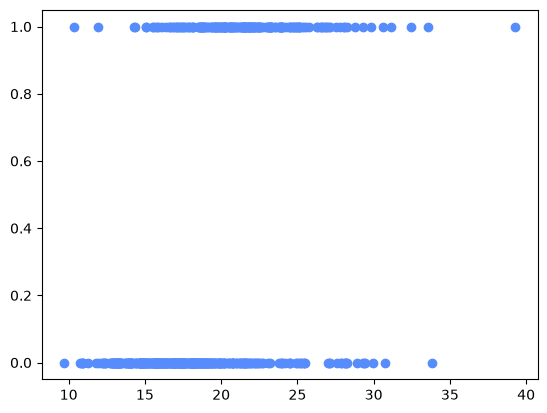

In [6]:
plt.scatter(df["texture_mean"], df["malignant"])
plt.show()

<Axes: >

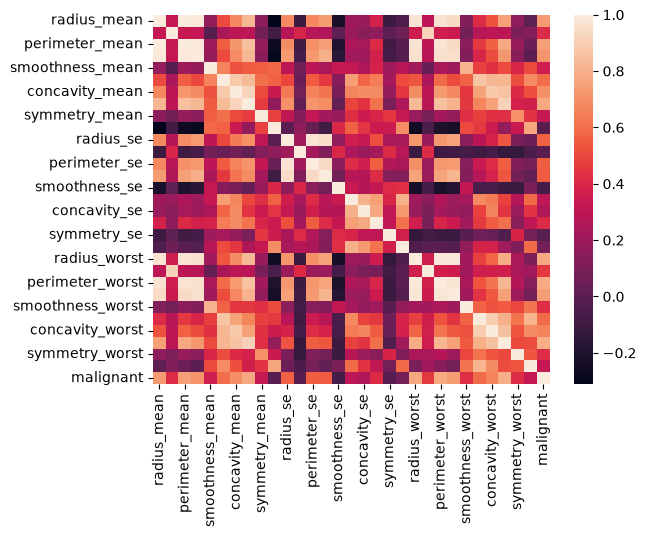

In [7]:
matrix_corr=df.corr()
sns.heatmap(matrix_corr)

### 4. Data Standardization

In [8]:
X=df.drop(columns=("malignant"))
Y=df["malignant"]

### 5. Train\test Split

In [9]:
X_train, X_test, Y_train, Y_test=train_test_split(X,Y, test_size=0.2, random_state=12345, stratify=Y)

In [10]:
df_train=X_train.copy()
df_train["malignant"]=Y_train

In [11]:
df_test=X_test.copy()
df_test["malignant"]=Y_test

In [12]:
pd.concat([df_train, df_test], ignore_index=True).plot(kind='scatter', x='texture_mean', y='smoothness_mean', color='malignant')

### 6. Modelling

#### 6.1 KNN

In [13]:
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train,Y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[bool](2,)","[False, True]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [14]:
sum(knn.predict(X_test) == Y_test)/len(X_test)

0.9473684210526315

Le modèle à donc une précision de 94% sur cet échantillon ce qui est très intéressant

In [15]:
scores = pd.DataFrame(data=[i for i in range(2, 300)], columns=['score'], index=range(2, 300))
scores['score'] = scores['score'].apply(lambda i: KNeighborsClassifier(n_neighbors=i).fit(X_train, Y_train).score(X_test, Y_test))
scores.plot()

On remarque donc que le nombre de "voisins" optimal est entre 68-97, on obtient le même score à chaque fois

In [16]:
confusion_matrix(Y_test, knn.predict(X_test),normalize='true')


array([[0.98611111, 0.01388889],
       [0.11904762, 0.88095238]])

#### 6.2 Logistic Regression

In [17]:
lreg=LogisticRegression(random_state=0, max_iter=10_000, penalty=None).fit(X_train, Y_train)

C:\Users\Leo\PycharmProjects\ML-Cancer-du-Sein\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\Leo\PycharmProjects\ML-Cancer-du-Sein\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 10000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=10000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
 

In [18]:
lreg.score(X_test, Y_test)

0.9649122807017544

In [19]:
# Code fully generated by GPT-4
def plot_coef(coef) :
    # Sort the coefficients by their absolute values
    sorted_coef = coef.abs().sort_values()

    # Get the original coefficients for coloring
    original_sorted_coef = coef.loc[sorted_coef.index]

    # Create a scatter plot with bars
    plt.figure(figsize=(8, 8))

    # Plot positive coefficients in blue, negative coefficients in red, and near-zero coefficients in grey
    colors = [
        'grey' if abs(coef) < 1e-08 else 'blue' if coef > 0 else 'red'
        for coef in original_sorted_coef
    ]

    plt.scatter(sorted_coef.values, sorted_coef.index, color=colors, zorder = 5)

    # Plot lines from the origin to the dots
    for i in range(len(sorted_coef)):
        plt.plot([0, sorted_coef.values[i]], [i, i], color='skyblue', lw = 2)

    plt.axvline(x=0, color='gray', linestyle='--', linewidth=1)
    plt.xlabel('Absolute Coefficient Value')
    plt.ylabel('Feature')
    plt.title('Regression Coefficients (Absolute Values)')

    plt.show()

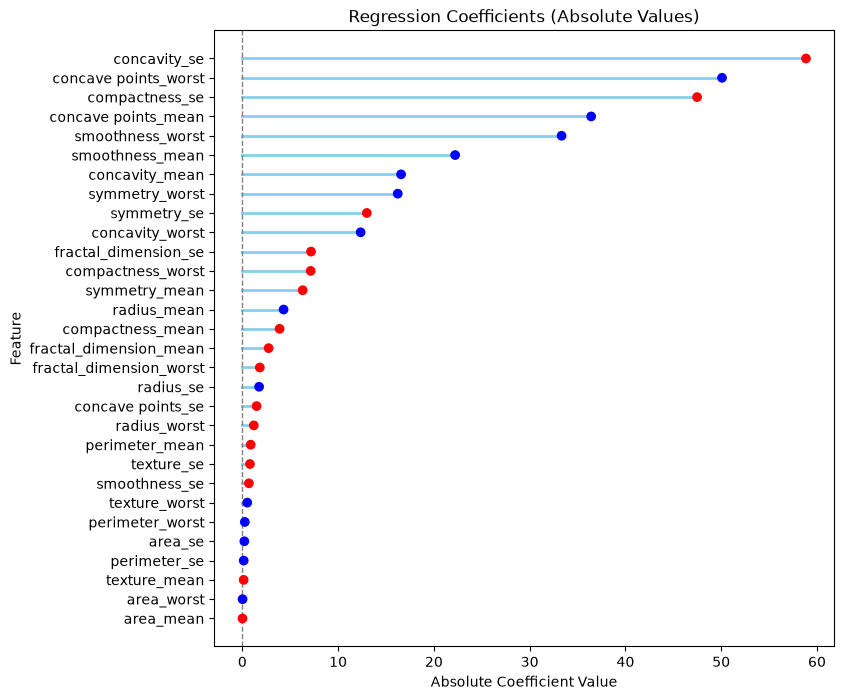

radius_mean                 4.307451
texture_mean               -0.134799
perimeter_mean             -0.870318
area_mean                  -0.012744
smoothness_mean            22.218569
compactness_mean           -3.890341
concavity_mean             16.573784
concave points_mean        36.420029
symmetry_mean              -6.300946
fractal_dimension_mean     -2.745687
radius_se                   1.748589
texture_se                 -0.794594
perimeter_se                0.141735
area_se                     0.207422
smoothness_se              -0.684395
compactness_se            -47.480799
concavity_se              -58.852117
concave points_se          -1.486001
symmetry_se               -12.993941
fractal_dimension_se       -7.170275
radius_worst               -1.194273
texture_worst               0.510827
perimeter_worst             0.256597
area_worst                  0.023628
smoothness_worst           33.332229
compactness_worst          -7.133908
concavity_worst            12.351016
c

In [20]:
coef = pd.Series(lreg.coef_[0], index=X.columns)
plot_coef(coef)
coef

Utilisation du Lasso

C:\Users\Leo\PycharmProjects\ML-Cancer-du-Sein\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


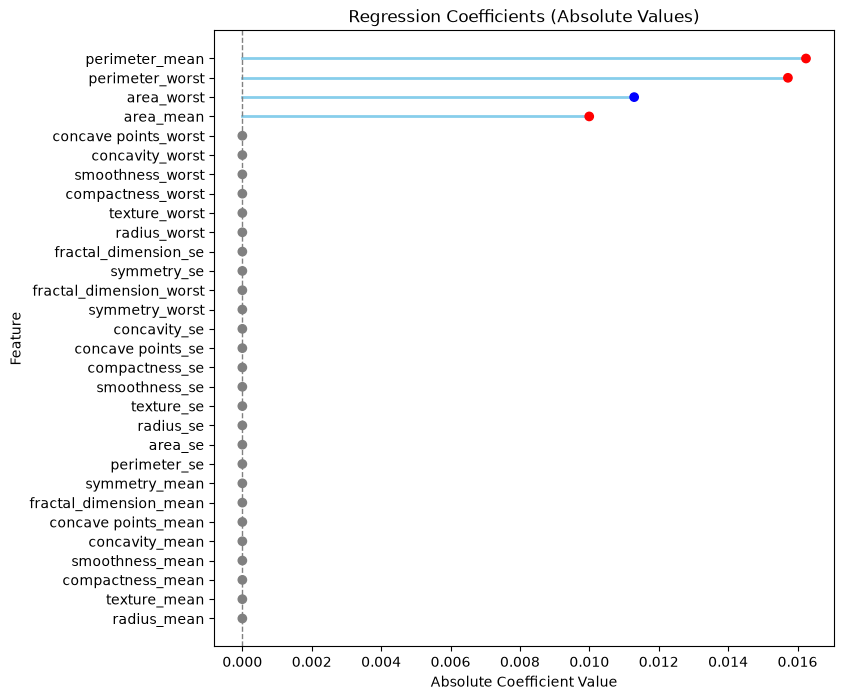

In [21]:
reg = LogisticRegression(l1_ratio=1, solver = 'saga', C = 0.001)
reg.fit(X_train, Y_train)

coef=pd.Series(reg.coef_[0], index=X.columns)
plot_coef(coef)

In [22]:
Y_pred=reg.predict(X_test)

confusion_matrix(Y_test, Y_pred,normalize='true')

array([[0.98611111, 0.01388889],
       [0.21428571, 0.78571429]])

In [23]:
accuracy_score(Y_test, Y_pred)

0.9122807017543859

In [24]:
reg.score(X_test,Y_test)

0.9122807017543859

On a donc une précision moins importante mais quand même intéressante car on prend en compte moins de paramètres